In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.metrics import mutual_info_score


In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [3]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count']

# Train with lead_score column? 
USE_LEAD_SCORE = False

if USE_LEAD_SCORE:
    numerical = numerical + ['lead_score']

In [7]:
for col in df.select_dtypes(include='object').columns:
    print(col, df[col].unique())

lead_source ['organic_search' 'social_media' 'referral' 'paid_ads' nan 'events']
industry ['technology' 'retail' 'manufacturing' 'education' 'healthcare' nan
 'finance']
employment_status ['employed' 'student' nan 'unemployed' 'self_employed']
location ['europe' 'south_america' nan 'north_america' 'africa' 'asia']


In [8]:
df[categorical] = df[categorical].fillna('NA')

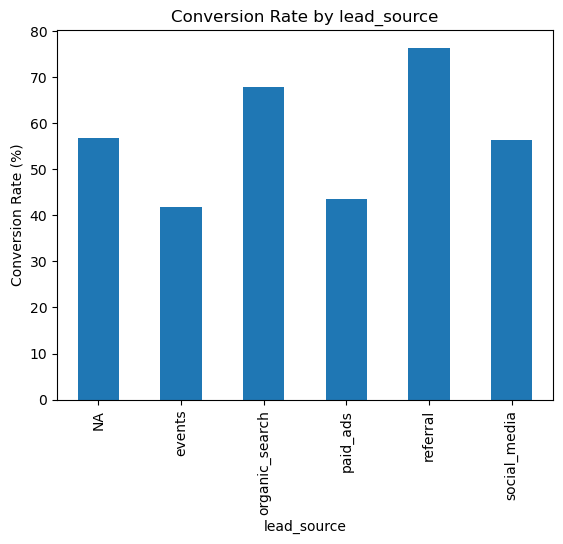

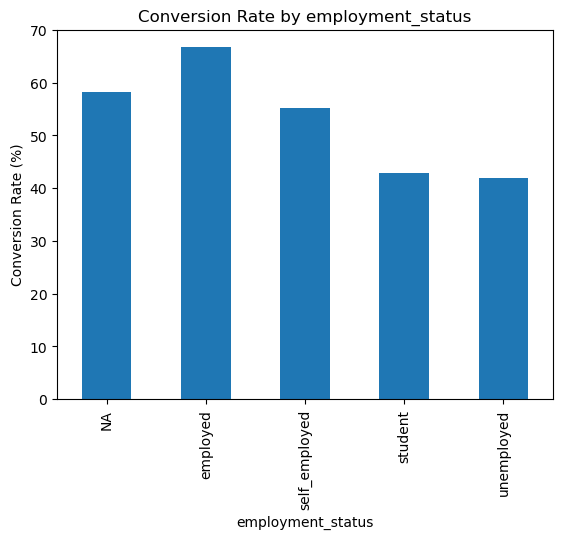

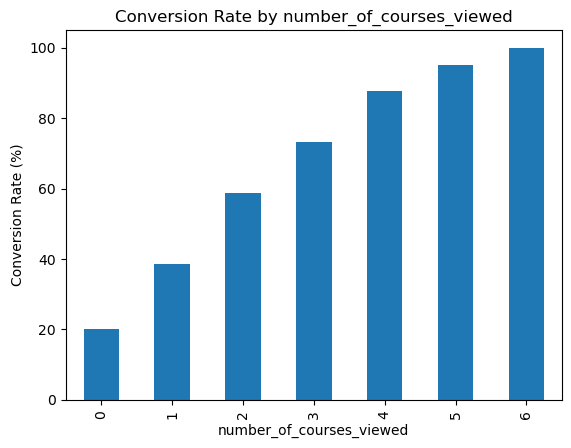

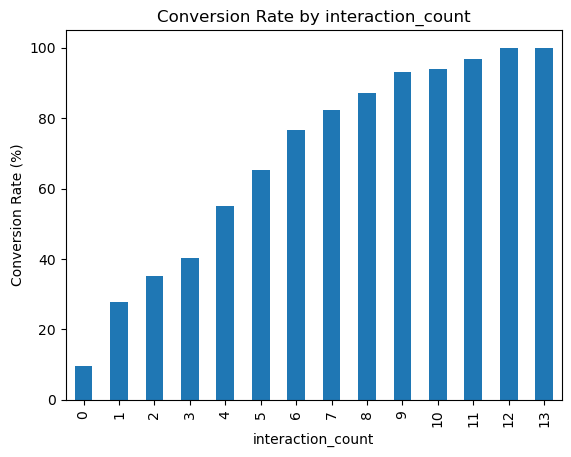

In [9]:
features = ['lead_source', 'employment_status',
            'number_of_courses_viewed', 'interaction_count']

for col in features:
    df.groupby(col)['converted'].mean().mul(100).plot(kind='bar')
    plt.title(f'Conversion Rate by {col}')
    plt.ylabel('Conversion Rate (%)')
    plt.show()

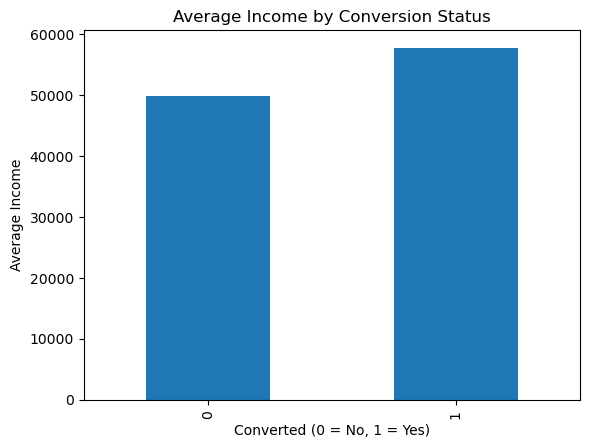

In [10]:
df.groupby('converted')['annual_income'].mean().plot(kind='bar')

plt.title('Average Income by Conversion Status')
plt.xlabel('Converted (0 = No, 1 = Yes)')
plt.ylabel('Average Income')
plt.show()

In [38]:
df.converted.mean()

np.float64(0.5766)

In [11]:
df[numerical + ['converted']].corr()

,annual_income,number_of_courses_viewed,interaction_count,converted
annual_income,1.000000,0.137542,0.106375,0.181752
number_of_courses_viewed,0.137542,1.000000,0.721609,0.395038
interaction_count,0.106375,0.721609,1.000000,0.448624
converted,0.181752,0.395038,0.448624,1.000000


In [12]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

In [13]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [14]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [15]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [16]:
def mi_score_cat(series):
    return mutual_info_score(series, y_train)

mi = df_train[categorical].apply(mi_score_cat)
mi.sort_values(ascending=False).round(2)

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

In [17]:
def train(df_train, y_train, model_type='logreg', C=1.0):
    df_train = df_train.copy()
    medians = df_train[numerical].median()          
    df_train[numerical] = df_train[numerical].fillna(medians)
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    dv.medians_ = medians                           

    if model_type == 'logreg':
        model = LogisticRegression(C=C, max_iter=3000)
    
    elif model_type == 'random_forest':
        model = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42)

    elif model_type == 'xgboost':
        model = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, eval_metric='logloss')

    else:
        raise ValueError(f"Unknown model type: {model_type}")
    
    model.fit(X_train, y_train)
    
    return dv, model

In [18]:
def predict(df, dv, model):
    df = df.copy()
    df[numerical] = df[numerical].fillna(dv.medians_)   
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [19]:
dv, model = train(df_train, y_train, model_type='logreg')
y_pred = predict(df_val, dv, model)

In [20]:
if USE_LEAD_SCORE:
    print("ROC AUC with lead_score:")
else:
    print("ROC AUC without lead_score:")

for model_type in ['logreg', 'random_forest', 'xgboost']:
    dv, model = train(df_train, y_train, model_type=model_type)
    y_pred = predict(df_val, dv, model)

    score = roc_auc_score(y_val, y_pred)
    print(f'{model_type} Score: {score:.3f}')

ROC AUC without lead_score:
logreg Score: 0.792
random_forest Score: 0.760
xgboost Score: 0.784


logreg Score: 0.792


random_forest Score: 0.760
xgboost Score: 0.784


In [21]:
def cross_validate(model_type='logreg', C=1.0, n_splits=5):
    kfold = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train, df_full_train.converted):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, model_type=model_type, C=C)
        y_pred = predict(df_val, dv, model)

        auc_score = roc_auc_score(y_val, y_pred)
        scores.append(auc_score)

    return scores

In [22]:
for model_type in ['logreg', 'random_forest', 'xgboost']:
    scores = cross_validate(model_type=model_type)
    print(f'{model_type} Mean: {np.mean(scores):.3f} +- Std: {np.std(scores):.3f}')

logreg Mean: 0.791 +- Std: 0.006
random_forest Mean: 0.744 +- Std: 0.008
xgboost Mean: 0.768 +- Std: 0.005


random_forest Mean: 0.744 +- Std: 0.008


xgboost Mean: 0.768 +- Std: 0.005


In [23]:
df[['interaction_count', 'number_of_courses_viewed', 'lead_score']].corr()

,interaction_count,number_of_courses_viewed,lead_score
interaction_count,1.000000,0.721609,0.928712
number_of_courses_viewed,0.721609,1.000000,0.769352
lead_score,0.928712,0.769352,1.000000


In [24]:
numerical_main = numerical.copy()
base_numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count']

rows = []
for use_ls in [False, True]:
    numerical = base_numerical + (['lead_score'] if use_ls else [])
    for model_type in ['logreg', 'random_forest', 'xgboost']:
        scores = cross_validate(model_type=model_type)
        rows.append({'model': model_type, 'lead_score': use_ls, 'cv_auc': np.mean(scores)})

numerical = numerical_main

pd.DataFrame(rows).pivot(index='model', columns='lead_score', values='cv_auc').round(3)

lead_score,False,True
model,,
logreg,0.791,0.795
random_forest,0.744,0.767
xgboost,0.768,0.774


In [25]:
def precision_recall(y_true, y_score):
    scores = []
    thresholds = np.linspace(0, 1, 101)

    actual_positive = (y_true == 1)
    actual_negative = (y_true == 0)

    for t in thresholds:
        predicted_positive = (y_score >= t)
        predicted_negative = (y_score < t)

        tp = (actual_positive & predicted_positive).sum()
        tn = (actual_negative & predicted_negative).sum()

        fp = (actual_negative & predicted_positive).sum()
        fn = (actual_positive & predicted_negative).sum()

        scores.append((t, tp, tn, fp, fn))

    columns = ['threshold', 'tp', 'tn', 'fp', 'fn']
    df_scores = pd.DataFrame(scores, columns=columns)
        
    df_scores['precision'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fp'])
    df_scores['recall'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fn'])
    df_scores['abs_precision_recall_diff'] = (df_scores['precision'] - df_scores['recall']).abs()
    df_scores['F1_score'] = 2 * (df_scores['precision'] * df_scores['recall']) / (df_scores['precision'] + df_scores['recall'])
    
    return df_scores
    

In [26]:
dv, model = train(df_train, y_train, model_type='logreg')
y_val_pred = predict(df_val, dv, model)

df_scores = precision_recall(y_val, y_val_pred)

In [37]:
max_f1 = df_scores['F1_score'].idxmax()
best_threshold = df_scores.loc[max_f1, 'threshold']
print(df_scores.loc[max_f1, ['threshold', 'precision', 'recall', 'F1_score']].round(3))



threshold    0.390
precision    0.728
recall       0.878
F1_score     0.796
Name: 39, dtype: float64


In [35]:
print(f'Best Threshold: {best_threshold}')

Best Threshold: 0.39


In [28]:
# Final model
dv, model = train(df_full_train, df_full_train.converted.values, model_type='logreg', C=1.0)
y_test_pred = predict(df_test, dv, model)

print(f"Test ROC-AUC: {roc_auc_score(y_test, y_test_pred):.3f}")

pred_label = (y_test_pred >= best_threshold)
tp = ((y_test == 1) & pred_label).sum()
fp = ((y_test == 0) & pred_label).sum()
fn = ((y_test == 1) & ~pred_label).sum()
print(f"At threshold {best_threshold:.2f}: precision={tp/(tp+fp):.3f}, recall={tp/(tp+fn):.3f}")

Test ROC-AUC: 0.782
At threshold 0.39: precision=0.709, recall=0.907
